In [1]:
# In practice dataset will store something like:

# duration_i = observed minutes

# status_i = 1 if unplug seen, 0 if censored

#EV under ToU vs. EV under 2-rates tariffs, potentially enriched with additional out of trial V2G data

# Initialisation

In [2]:
import polars as pl
import numpy as np

import lifelines as ll
import matplotlib.pyplot as plt

## Functions

In [3]:
# def calculate_duration(df_flagged):

#     charges = (
#         df_flagged
#         .filter(pl.col("ev_like"))
#         .sort(["household", "ts"])
#     )

#     # detect new episode when gap > 1 hour
#     charges = charges.with_columns(
#         (
#             (pl.col("ts")
#             - pl.col("ts").shift(1).over("household")
#         ).dt.total_minutes()/60).fill_null(1).alias("gap_h")
#     )

#     charges = charges.with_columns(
#         (pl.col("gap_h") > 1).cast(pl.Int8).alias("new_episode")
#     )

#     charges = charges.with_columns(
#         pl.col("new_episode").cum_sum().over("household").alias("episode_id")
#     )

#     episodes = (
#         charges
#         .group_by(["household", "episode_id"])
#         .agg([
#             pl.col("ts").min().alias("start_ts"),
#             (pl.col("ts").max() + pl.duration(minutes=30)).alias("end_ts"),
#         ])
#         .sort(["household", "start_ts"])
#     )

#     return episodes

In [4]:
def calculate_gaps(episodes):
    gap_times = (
    episodes
    .with_columns(
        pl.col("start_ts").shift(-1).over("household").alias("next_start")
    )
    .filter(pl.col("next_start").is_not_null())
    .with_columns(
        ((pl.col("next_start") - pl.col("end_ts")).dt.total_minutes()/60).alias("gap_hours_till_next_charge")
    )
    .select(["household", "start_ts", "end_ts", "next_start", "gap_hours_till_next_charge"])
    )

    return gap_times

In [5]:
def gen_df_events(df_flagged):

    charges = (
        df_flagged
        .filter(pl.col("ev_like"))
        .sort(["household", "ts"])
    )

    # detect new episode when gap > 1 hour
    charges = charges.with_columns(
        (
            (pl.col("ts")
            - pl.col("ts").shift(1).over("household")
        ).dt.total_minutes()/60).fill_null(1).alias("gap_h")
    )

    charges = charges.with_columns(
        (pl.col("gap_h") > 1).cast(pl.Int8).alias("new_episode")
    )

    charges = charges.with_columns(
        pl.col("new_episode").cum_sum().over("household").alias("episode_id")
    )

    episodes = (
        charges
        .group_by(["household", "episode_id"])
        .agg([
            pl.col("ts").min().alias("start_ts"),
            (pl.col("ts").max() + pl.duration(minutes=30)).alias("end_ts"),
        ])
        .sort(["household", "start_ts"])
    )

    return episodes

In [6]:
def plot_client_with_charging(df_flagged: pl.DataFrame, household_name: str):
    d = (
        df_flagged
        .filter(pl.col("household") == household_name)
        .select(["ts", "kwh", "ev_like"])
        .sort("ts")
        .to_pandas()
    )

    fig, ax = plt.subplots(figsize=(12,4))
    ax.plot(d["ts"], d["kwh"], label="Consumption (kWh)")

    # highlight flagged hours
    m = d["ev_like"].astype(bool)
    ax.scatter(d.loc[m, "ts"], d.loc[m, "kwh"], color="red", s=12, label="Charging events")

    ax.set_title(f"Household {household_name}: consumption with EV charging highlighted")
    ax.set_ylabel("kWh per hour")
    ax.legend()
    plt.tight_layout()
    plt.show()


In [7]:
def clean_df(data: str):
    path = f"../data/{data}ConsolideNEW.csv"
    df = pl.read_csv(path)

    time_col = df.columns[0]  # the unnamed time column (first column)

    df = (
        df.with_columns(
            [
                pl.col(time_col).str.strptime(pl.Datetime, strict=False).alias("ts"),
                pl.exclude(time_col).cast(pl.Float64),
            ]
        )
    ).drop([df.columns[0]])

    df = (
    df.unpivot(index=["ts"])
      .rename({"variable": "household", "value": "kwh"})
      .sort(["household", "ts"])
      .with_columns([
          pl.col("ts")
            .dt.strftime("%w")
            .cast(pl.Int8)
            .is_in([0, 6])
            .cast(pl.Int8)
            .alias("is_weekend"),

          pl.col("ts").dt.month().alias("month"),
      ])
      .with_columns([
          # season
          pl.when(pl.col("month").is_in([12, 1, 2]))
            .then(pl.lit("winter"))
            .when(pl.col("month").is_in([3, 4, 5]))
            .then(pl.lit("spring"))
            .when(pl.col("month").is_in([6, 7, 8]))
            .then(pl.lit("summer"))
            .otherwise(pl.lit("autumn"))
            .alias("season"),

          # time period
          pl.when(pl.col("is_weekend") == 1)
            # WEEKEND
            .then(
                pl.when(pl.col("ts").dt.hour() < 8)
                  .then(pl.lit("offpeak"))
                  .when(pl.col("ts").dt.hour().is_between(16, 20))
                  .then(pl.lit("peak"))
                  .otherwise(pl.lit("mid"))
            )
            # WEEKDAY
            .otherwise(
                pl.when(pl.col("ts").dt.hour() < 8)
                  .then(pl.lit("offpeak"))
                  .otherwise(pl.lit("mid"))
            )
            .alias("time_period"),
      ])
      .drop("month")
)
    
    df = df.with_columns(
    pl.col("kwh").fill_null(0)
)


    return df


# Exploration

In [8]:
df_C = clean_df('controle')
df_I = clean_df('intervention')

In [9]:
df_C.head()

ts,household,kwh,is_weekend,season,time_period
datetime[μs],str,f64,i8,str,str
2025-01-02 00:00:00,"""03efd9cce89d44d9a78d085c240476…",0.157,0,"""winter""","""offpeak"""
2025-01-02 00:30:00,"""03efd9cce89d44d9a78d085c240476…",0.151,0,"""winter""","""offpeak"""
2025-01-02 01:00:00,"""03efd9cce89d44d9a78d085c240476…",0.475,0,"""winter""","""offpeak"""
2025-01-02 01:30:00,"""03efd9cce89d44d9a78d085c240476…",0.14,0,"""winter""","""offpeak"""
2025-01-02 02:00:00,"""03efd9cce89d44d9a78d085c240476…",0.347,0,"""winter""","""offpeak"""


In [10]:
print(df_C['household'].unique().shape,
      df_I['household'].unique().shape)

(89,) (110,)


In [11]:
# Real data duration
clients_duration = df_C.filter(pl.col('kwh') > 0.1).group_by(['household']).agg([
            (pl.col("ts").max() - pl.col("ts").min()).alias("no_zero_duration"),
        ]).sort('no_zero_duration')

clients_duration

household,no_zero_duration
str,duration[μs]
"""79f6f18dc8a3b0f9d45859ff53b6c4…",172d 30m
"""492df8bdb234b2aee443896a039df9…",178d 12h 30m
"""58f08adbcb5a124d347040fbae3e2e…",208d 21h
"""e9841079beed2eea5f907cfa4b90c7…",212d 15h 30m
"""ac1784c15af6f946700d462165ad43…",213d 1h
…,…
"""76322de420bbb1294ed8af38d5629f…",243d 30m
"""f6e4aafb7e493d35535a02e12ff218…",243d 30m
"""2ec512b154d1a04ea4d9e31f7dbf44…",243d 30m


## Removing unexploitable data 

### Inactive or not?

In [40]:
df_C

ts,household,kwh,is_weekend,season,time_period
datetime[μs],str,f64,i8,str,str
2025-01-02 00:00:00,"""03efd9cce89d44d9a78d085c240476…",0.157,0,"""winter""","""offpeak"""
2025-01-02 00:30:00,"""03efd9cce89d44d9a78d085c240476…",0.151,0,"""winter""","""offpeak"""
2025-01-02 01:00:00,"""03efd9cce89d44d9a78d085c240476…",0.475,0,"""winter""","""offpeak"""
2025-01-02 01:30:00,"""03efd9cce89d44d9a78d085c240476…",0.14,0,"""winter""","""offpeak"""
2025-01-02 02:00:00,"""03efd9cce89d44d9a78d085c240476…",0.347,0,"""winter""","""offpeak"""
…,…,…,…,…,…
2025-09-01 23:00:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.184,0,"""autumn""","""mid"""
2025-09-01 23:30:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.216,0,"""autumn""","""mid"""
2025-09-02 00:00:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.141,0,"""autumn""","""offpeak"""


In [41]:
# Remove inactive peiods : vacation, metering issue...

INACTIVE_KWH = 0.05 #0.1 but half hourly
PROLONGED_DAYS = 1  

df = df_C.with_columns(
    (pl.col("kwh") < INACTIVE_KWH).alias("inactive")
)

inactive_runs = (
    df
    .sort(["household", "ts"])
    .with_columns(
        (
            pl.col("inactive")
            &
            ~pl.col("inactive").shift(1).over("household").fill_null(False) #“Was the previous record in this household active?”
        ).cast(pl.Int8).alias("start_run")
    )
    .with_columns(
        pl.col("start_run").cum_sum().over("household").alias("run_id")
    )
)

inactive_ep = (
    inactive_runs
    .filter(pl.col("inactive"))
    .group_by(["household", "run_id"])
    .agg([
        pl.col("ts").min().alias("start"),
        pl.col("ts").max().alias("end"),
        pl.count().alias("n_slots"),
    ])
    .with_columns(
        (pl.col("n_slots") / 48).alias("days")  # 48 half-hours/day
    )
)

inactive_ep = inactive_ep.with_columns(
    (pl.col("days") >= PROLONGED_DAYS).alias("prolonged")
)

list_inactive = inactive_ep['household'].unique().to_list()

# inactive_runs.filter(pl.col('inactive'))

inactive_ep.filter(pl.col('prolonged'))



C:\Users\duval1e\AppData\Local\Temp\ipykernel_14760\3946326447.py:32: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("n_slots"),


household,run_id,start,end,n_slots,days,prolonged
str,i64,datetime[μs],datetime[μs],u32,f64,bool
"""e6911bf46a55a9421acadb9caa874f…",128,2025-05-05 11:30:00,2025-05-07 17:30:00,109,2.270833,true
"""4b3461e0810dbd5bc9c48dcb9fdaba…",115,2025-05-08 05:00:00,2025-05-10 13:00:00,113,2.354167,true
"""a1a1fef2989f93b76e01bb9932b512…",161,2025-08-23 03:00:00,2025-09-02 01:00:00,477,9.9375,true
"""e6911bf46a55a9421acadb9caa874f…",217,2025-08-03 16:00:00,2025-08-04 16:30:00,50,1.041667,true
"""79f6f18dc8a3b0f9d45859ff53b6c4…",12,2025-06-10 01:00:00,2025-07-07 00:30:00,1296,27.0,true
…,…,…,…,…,…,…
"""7181efdd5015c0f83b33c0265d5956…",12,2025-08-07 01:00:00,2025-08-30 00:30:00,1104,23.0,true
"""79f6f18dc8a3b0f9d45859ff53b6c4…",7,2025-05-08 01:00:00,2025-05-18 00:30:00,480,10.0,true
"""a1a1fef2989f93b76e01bb9932b512…",140,2025-04-16 03:00:00,2025-04-18 03:30:00,98,2.041667,true


In [42]:
df_C

ts,household,kwh,is_weekend,season,time_period
datetime[μs],str,f64,i8,str,str
2025-01-02 00:00:00,"""03efd9cce89d44d9a78d085c240476…",0.157,0,"""winter""","""offpeak"""
2025-01-02 00:30:00,"""03efd9cce89d44d9a78d085c240476…",0.151,0,"""winter""","""offpeak"""
2025-01-02 01:00:00,"""03efd9cce89d44d9a78d085c240476…",0.475,0,"""winter""","""offpeak"""
2025-01-02 01:30:00,"""03efd9cce89d44d9a78d085c240476…",0.14,0,"""winter""","""offpeak"""
2025-01-02 02:00:00,"""03efd9cce89d44d9a78d085c240476…",0.347,0,"""winter""","""offpeak"""
…,…,…,…,…,…
2025-09-01 23:00:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.184,0,"""autumn""","""mid"""
2025-09-01 23:30:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.216,0,"""autumn""","""mid"""
2025-09-02 00:00:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.141,0,"""autumn""","""offpeak"""


In [43]:
## Removing them from main dataset

inactive_mask = (
    inactive_runs
    .join(
        inactive_ep.filter(pl.col("prolonged"))
        .select(["household", "run_id"]),
        on=["household", "run_id"],
        how="inner"
    )
    .select(["household", "ts"])
)
df_C_clean = df_C.join(
    inactive_mask,
    on=["household", "ts"],
    how="anti"
)
df_C_clean

ts,household,kwh,is_weekend,season,time_period
datetime[μs],str,f64,i8,str,str
2025-01-02 00:00:00,"""03efd9cce89d44d9a78d085c240476…",0.157,0,"""winter""","""offpeak"""
2025-01-02 00:30:00,"""03efd9cce89d44d9a78d085c240476…",0.151,0,"""winter""","""offpeak"""
2025-01-02 01:00:00,"""03efd9cce89d44d9a78d085c240476…",0.475,0,"""winter""","""offpeak"""
2025-01-02 01:30:00,"""03efd9cce89d44d9a78d085c240476…",0.14,0,"""winter""","""offpeak"""
2025-01-02 02:00:00,"""03efd9cce89d44d9a78d085c240476…",0.347,0,"""winter""","""offpeak"""
…,…,…,…,…,…
2025-09-01 23:00:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.184,0,"""autumn""","""mid"""
2025-09-01 23:30:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.216,0,"""autumn""","""mid"""
2025-09-02 00:00:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.141,0,"""autumn""","""offpeak"""


### EV converted or not?

In [44]:
#Clients with big quantile 95 plateaux
#from the graph lets choose to consider a jump from 2.7 
#wich is reasonable cuz usually CHARGER_KW_OPTIONS = [2.3, 3.6, 7.0]

EV_JUMP = 1.8  # kWh or equivalent monthly peak jump granny charging is common for Early EV adopters

diff_q = (
    df_C
    .sort("ts")
    .group_by_dynamic(
        index_column="ts",
        every="1w",
        closed="left",
        group_by="household"
    )
    .agg(
        pl.col("kwh").quantile(0.95).alias("q95")
    ) ### find max of all monthly maximums to see if a big jump happens (also min of all max course)
    .sort(["household", "ts"])
)

diff_q = diff_q.with_columns(
    pl.col("q95").diff().over("household").alias("dq95")
)

diff_q = diff_q.with_columns(
    (pl.col("dq95") > EV_JUMP).alias("jump_candidate")
)

diff_q = diff_q.with_columns(
    pl.col("q95")
      .rolling_mean(13) ## duration of a season
      .shift(-12) # to compute forward
      .over("household")
      .alias("q95_smooth")
)

diff_q = diff_q.with_columns(
    (
        pl.col("jump_candidate")
        &
        (
            pl.col("q95_smooth")
            >
            pl.col("q95").shift(1).over("household") + EV_JUMP
        )
    ).alias("ev_adopted")
)

ev_start = (
    diff_q
    .filter(pl.col("ev_adopted"))
    .group_by("household")
    .agg(pl.col("ts").min().alias("ev_start_ts"))
)

list_converted = ev_start['household'].unique().to_list()

In [52]:
## Removing them from main dataset

pre_ev_mask = (
    df_C_clean
    .join(ev_start, on="household", how="inner")
    .filter(pl.col("ts") < pl.col("ev_start_ts"))
    .select(["household", "ts"])
)

df_C_post_ev = df_C_clean.join(
    pre_ev_mask,
    on=["household", "ts"],
    how="anti"
)

df_C_post_ev

ts,household,kwh,is_weekend,season,time_period
datetime[μs],str,f64,i8,str,str
2025-01-02 00:00:00,"""03efd9cce89d44d9a78d085c240476…",0.157,0,"""winter""","""offpeak"""
2025-01-02 00:30:00,"""03efd9cce89d44d9a78d085c240476…",0.151,0,"""winter""","""offpeak"""
2025-01-02 01:00:00,"""03efd9cce89d44d9a78d085c240476…",0.475,0,"""winter""","""offpeak"""
2025-01-02 01:30:00,"""03efd9cce89d44d9a78d085c240476…",0.14,0,"""winter""","""offpeak"""
2025-01-02 02:00:00,"""03efd9cce89d44d9a78d085c240476…",0.347,0,"""winter""","""offpeak"""
…,…,…,…,…,…
2025-09-01 23:00:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.184,0,"""autumn""","""mid"""
2025-09-01 23:30:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.216,0,"""autumn""","""mid"""
2025-09-02 00:00:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.141,0,"""autumn""","""offpeak"""


In [53]:
# Every household starts at its EV adoption time
check = (
    df_C_post_ev
    .group_by("household")
    .agg(pl.col("ts").min().alias("first_ts"))
    .join(ev_start, on="household")
    .with_columns(
        (pl.col("first_ts") == pl.col("ev_start_ts")).alias("ok")
    )
)

check.filter(~pl.col("ok"))


household,first_ts,ev_start_ts,ok
str,datetime[μs],datetime[μs],bool


### More plots

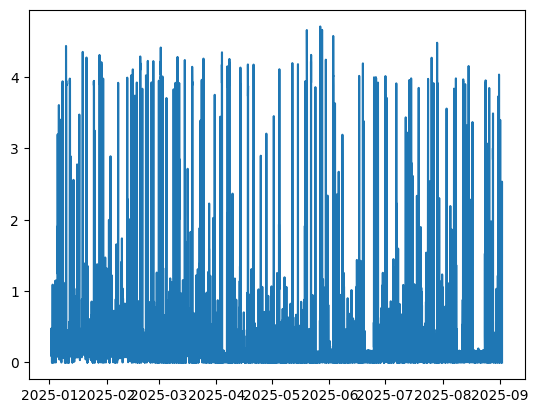

In [54]:
client = df_C_post_ev.filter(pl.col('household') == "03efd9cce89d44d9a78d085c240476ebddb7c2f7282e9b76ee18ef4a83ef34d3")
plt.plot(client['ts'], client['kwh'])
plt.show()

Text(0.5, 1.0, 'Distribution of values above which we consider a charging event')

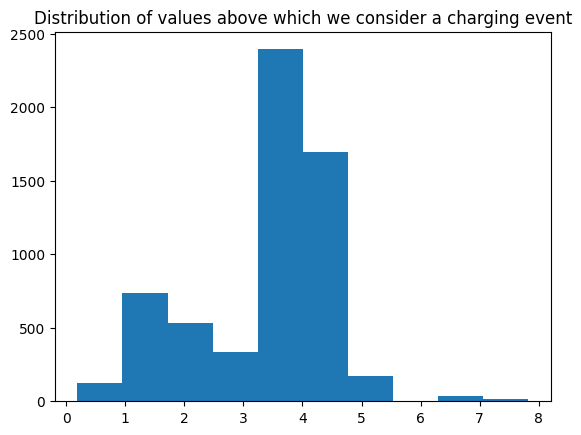

In [58]:
# high quantile method

Q = 0.99 # threshold quantile 

cols = ["household", "is_weekend", "season", 'time_period']

ev_threshold = (
    df_C_post_ev
    .group_by(cols)
    .agg(pl.col("kwh").quantile(Q, interpolation="nearest").alias("ev_threshold"))  
)

df_flagged_C = (
    df_C_post_ev
    .join(ev_threshold, on=cols)
    .with_columns(
        (
            pl.col("kwh")
            > pl.max_horizontal(pl.col("ev_threshold"), pl.lit(1.8))
        ).alias("ev_like")
    )
)

# Just the times to highlight
charge_events = df_flagged_C.filter(pl.col("ev_like")).select(
    cols + ["ts", "kwh", "ev_threshold"]
)

plt.hist(charge_events['ev_threshold'])
plt.title('Distribution of values above which we consider a charging event')

Text(0.5, 1.0, 'Distribution of consumption plateaux differences across all households')

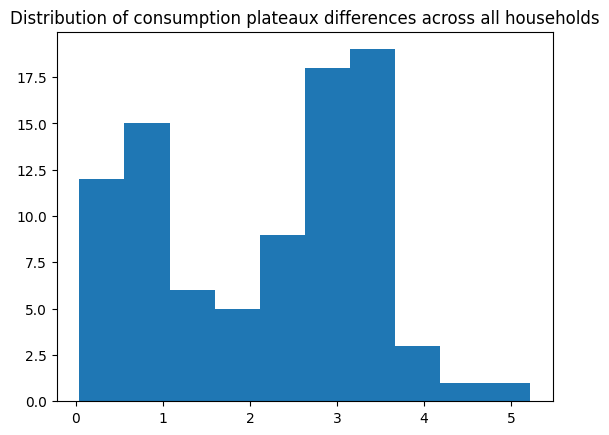

In [56]:
# gaps between high plateaux? JUST FOR VISU

df = (
    df_C_post_ev
    .sort("ts")
    .group_by_dynamic(
        index_column="ts",
        every="1mo",
        closed="left",
        group_by="household"
    )
    .agg(
        pl.col("kwh").quantile(0.95).alias("q95")
    ) ### find max of all monthly maximums to see if a big jump happens (also min of all max course)
    .group_by("household")
    .agg([
        (pl.col("q95").max()-pl.col("q95").min()).alias("diff_q95"), 
    ])
)

plt.hist(df['diff_q95'])
plt.title('Distribution of consumption plateaux differences across all households')

Text(0.5, 1.0, 'Distribution of consumption max differences across all households')

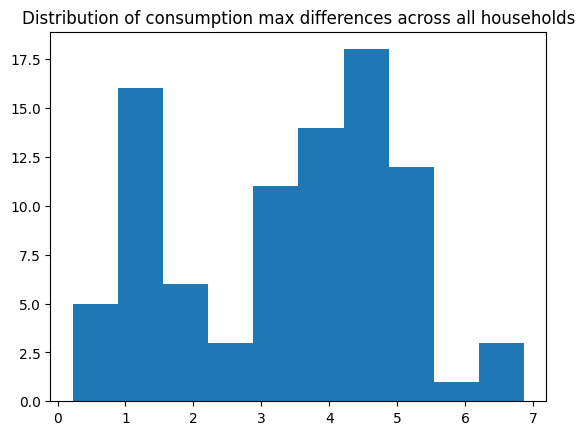

In [57]:
# gaps between high plateaux? JUST FOR VISU 

df = (
    df_C_post_ev
    .sort("ts")
    .group_by_dynamic(
        index_column="ts",
        every="1mo",
        closed="left",
        group_by="household"
    )
    .agg(
        pl.col("kwh").max().alias("window_max")
    ) ### find max of all monthly maximums to see if a big jump happens (also min of all max course)
    .group_by("household")
    .agg([
        (pl.col("window_max").max()-pl.col("window_max").min()).alias("diff_window_max"), 
    ])
)

plt.hist(df['diff_window_max'])
plt.title('Distribution of consumption max differences across all households')

In [51]:
#Clients with big MAX plateaux
#from the graph lets choose to consider a jump from 2.7 
#wich is reasonable cuz usually CHARGER_KW_OPTIONS = [2.3, 3.6, 7.0]

# EV_JUMP = 2.7

# df = (
#     df_C
#     .sort("ts")
#     .group_by_dynamic(
#         index_column="ts",
#         every="1mo",
#         closed="left",
#         group_by="household"
#     )
#     .agg(
#         pl.col("kwh").max().alias("window_max")
#     )
#     .group_by("household")
          
#     .agg([pl.col("window_max").max().alias("max_window_max"),
#           pl.col("window_max").min().alias("min_window_max"),
#         (pl.col("window_max").max()-pl.col("window_max").min()).alias("diff_window_max"),
#     ])
# )
# print(df.filter(pl.col('diff_window_max') > EV_JUMP))

# list_adopters_ev = (df.filter(pl.col('diff_window_max') > EV_JUMP)['household'].to_list())

## Creation of events df

In [21]:
# frequency
freq_events = charge_events.group_by(["household"]).agg([
            pl.col("ts").count().alias("nb_of_events"),
            ((pl.col('ts').max() - pl.col("ts").min()).dt.total_days()/pl.col("ts").count()).alias("freq"),
        ]).sort(["freq", "nb_of_events"])

# plt.plot(b["nb_of_events"])
freq_events

household,nb_of_events,freq
str,u32,f64
"""123c7e64de27fc8e47ced9e8ac651a…",65,1.353846
"""27b02a005ce819109184d5b5cf1aa1…",99,1.717172
"""58f08adbcb5a124d347040fbae3e2e…",112,1.794643
"""85aa9e4bd7cba7b61ae01d85c00b70…",116,1.87069
"""04799c25a413ad464645964deabb27…",117,1.871795
…,…,…
"""a1a1fef2989f93b76e01bb9932b512…",40,5.675
"""e6911bf46a55a9421acadb9caa874f…",38,5.868421
"""8e19d5580ce5a3d120ac3eee05eb02…",37,6.27027


In [22]:
# median + charger excess

# Q = 0.5               # baseline quantile 
# CHARGER_KW_OPTIONS = [2.3, 3.6, 7.0]
# TOL = 0.35

# #control
# ##baseline sur energie soutenue 1h 

# cols = ["household", "is_weekend", "season", 'time_period']

# baseline = (
#     df_C
#     .group_by(cols)
#     .agg(pl.col("kwh").quantile(Q, interpolation="nearest").alias("baseline"))  
# )

# df_flagged_C = (
#     df_C
#     .join(baseline, on=cols)
#     .with_columns([
#         (pl.col("kwh") - pl.col("baseline")).clip(lower_bound = 0).alias("excess_kwh"),
#     ])
#     .with_columns([
#         # flag if excess matches any typical charger size (within tolerance)
#         pl.any_horizontal([
#             pl.col("excess_kwh").is_between(kw * (1 - TOL), kw * (1 + TOL)) #--- ev no ev
#             for kw in CHARGER_KW_OPTIONS
#         ]).alias("ev_like"),
#     ])
# )

# # Just the times to highlight
# df_flagged_C.filter(pl.col("ev_like")).select(
#     ["ts", "season", "household", "kwh", "baseline", "excess_kwh", 'time_period']
# )


# Survival models

## Gap-time model

### Control

In [23]:
episodes = gen_df_events(df_flagged_C)
episodes

household,episode_id,start_ts,end_ts
str,i64,datetime[μs],datetime[μs]
"""03efd9cce89d44d9a78d085c240476…",0,2025-01-05 12:30:00,2025-01-05 13:30:00
"""03efd9cce89d44d9a78d085c240476…",1,2025-01-05 18:30:00,2025-01-05 19:00:00
"""03efd9cce89d44d9a78d085c240476…",2,2025-01-10 00:30:00,2025-01-10 01:00:00
"""03efd9cce89d44d9a78d085c240476…",3,2025-01-12 11:30:00,2025-01-12 12:00:00
"""03efd9cce89d44d9a78d085c240476…",4,2025-01-12 18:00:00,2025-01-12 18:30:00
…,…,…,…
"""fff1cfde616f1b03a9b23a1d5385bb…",20,2025-06-22 00:30:00,2025-06-22 02:00:00
"""fff1cfde616f1b03a9b23a1d5385bb…",21,2025-07-05 00:30:00,2025-07-05 01:00:00
"""fff1cfde616f1b03a9b23a1d5385bb…",22,2025-07-11 01:30:00,2025-07-11 02:00:00


In [24]:
gap_times = calculate_gaps(episodes)
gap_times

household,start_ts,end_ts,next_start,gap_hours_till_next_charge
str,datetime[μs],datetime[μs],datetime[μs],f64
"""03efd9cce89d44d9a78d085c240476…",2025-01-05 12:30:00,2025-01-05 13:30:00,2025-01-05 18:30:00,5.0
"""03efd9cce89d44d9a78d085c240476…",2025-01-05 18:30:00,2025-01-05 19:00:00,2025-01-10 00:30:00,101.5
"""03efd9cce89d44d9a78d085c240476…",2025-01-10 00:30:00,2025-01-10 01:00:00,2025-01-12 11:30:00,58.5
"""03efd9cce89d44d9a78d085c240476…",2025-01-12 11:30:00,2025-01-12 12:00:00,2025-01-12 18:00:00,6.0
"""03efd9cce89d44d9a78d085c240476…",2025-01-12 18:00:00,2025-01-12 18:30:00,2025-01-19 00:30:00,150.0
…,…,…,…,…
"""fff1cfde616f1b03a9b23a1d5385bb…",2025-06-13 02:30:00,2025-06-13 04:30:00,2025-06-22 00:30:00,212.0
"""fff1cfde616f1b03a9b23a1d5385bb…",2025-06-22 00:30:00,2025-06-22 02:00:00,2025-07-05 00:30:00,310.5
"""fff1cfde616f1b03a9b23a1d5385bb…",2025-07-05 00:30:00,2025-07-05 01:00:00,2025-07-11 01:30:00,144.5


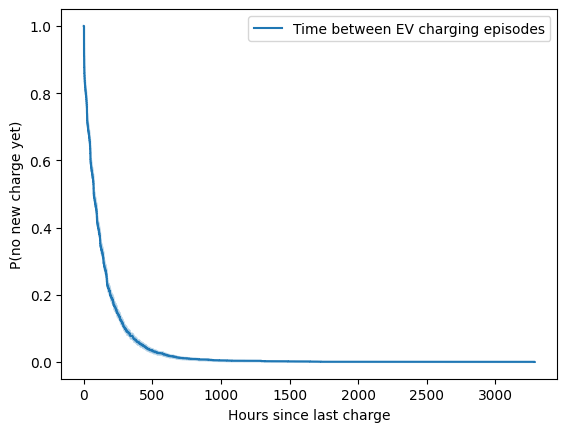

In [25]:
# How long after a charge does the next charge happen?

kmf = ll.KaplanMeierFitter()
kmf.fit(gap_times["gap_hours_till_next_charge"], label="Time between EV charging episodes")
kmf.plot_survival_function()

plt.xlabel("Hours since last charge")
plt.ylabel("P(no new charge yet)")
plt.show()

#Steep drop = frequent charging

### Intervention

In [26]:
episodes_I = gen_df_events(df_flagged_I)
gap_times_I = calculate_gaps(episodes_I)
gap_times_I

NameError: name 'df_flagged_I' is not defined

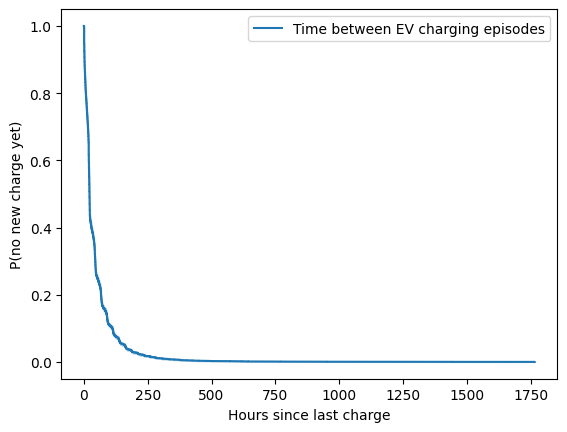

In [ ]:
# How long after a charge does the next charge happen?

kmf = ll.KaplanMeierFitter()
kmf.fit(gap_times_I["gap_hours_till_next_charge"], label="Time between EV charging episodes")
kmf.plot_survival_function()

plt.xlabel("Hours since last charge")
plt.ylabel("P(no new charge yet)")
plt.show()

#Steep drop = frequent charging

## Andersen–Gill Cox model

household,start,stop,event
str,datetime[μs],datetime[μs],i8
"""03efd9cce89d44d9a78d085c240476…",2025-01-02 00:00:00,2025-01-02 00:30:00,0
"""03efd9cce89d44d9a78d085c240476…",2025-01-02 00:30:00,2025-01-02 01:00:00,0
"""03efd9cce89d44d9a78d085c240476…",2025-01-02 01:00:00,2025-01-02 01:30:00,0
"""03efd9cce89d44d9a78d085c240476…",2025-01-02 01:30:00,2025-01-02 02:00:00,0
"""03efd9cce89d44d9a78d085c240476…",2025-01-02 02:00:00,2025-01-02 02:30:00,0
…,…,…,…
"""fff1cfde616f1b03a9b23a1d5385bb…",2025-09-01 22:30:00,2025-09-01 23:00:00,0
"""fff1cfde616f1b03a9b23a1d5385bb…",2025-09-01 23:00:00,2025-09-01 23:30:00,0
"""fff1cfde616f1b03a9b23a1d5385bb…",2025-09-01 23:30:00,2025-09-02 00:00:00,0


In [ ]:
# What factors increase charging rate over time?

#Andersen–Gill Cox model: each household as a process over time

# cph = ll.CoxPHFitter()
# cph.fit(
#     df_cp.to_pandas(),
#     duration_col="duration",
#     event_col="event",
#     entry_col="start_t",
#     cluster_col="household"   
# )

# cph.print_summary()